<p class="hz-kicker">Week 2 · Self-paced lab</p>

# Seasons by hotel

The general manager wants to know how Altamar's three hotels really differ: when each one is expensive, when it is cheap, and which bookings are likely to cancel. In this lab you slice the clean file yourself, change the settings, and write three findings with numbers the code prints.

<ul class="hz-lesson-meta"><li>≈ 2 hours</li><li>5 tasks</li><li>Runs in your browser</li><li>Graded quiz</li></ul>

**From the live session:**

- The raw file had duplicates, misspellings, impossible rates and gaps. Cleaning took it from 6,060 to 5,964 bookings, each decision written in a cleaning log.
- A **mask** (`df["hotel"] == "Santiago"`) keeps the rows you need; `&` means AND, `|` means OR.
- **groupby** and **pivot tables** answer "what is the average X for each Y?"; the mean of `canceled` is the cancellation rate.

**Run this cell first.** You don't need to read it: it loads the clean file and adds the arrival month.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
HOTELS = ["Santiago", "Viña del Mar", "Puerto Varas"]
ROOMS = ["Standard", "Superior", "Suite"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

df = pd.read_csv(DATA + "altamar_bookings_clean.csv")
df["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month
print(f"{len(df):,} bookings, cancellation rate {df['canceled'].mean():.1%}")

5,964 bookings, cancellation rate 33.7%


## <span class="hz-step-n">01</span> One hotel, one season

Pick a hotel and a range of arrival months, and compare those bookings with the same hotel's other months. The code builds two masks and combines them with `&`, as in the simulator.

<div class="hz-widget" data-widget="mask-filter">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Lab/">open this session on the course website</a> to use it.</p>
</div>

Change the settings and run the cell. It prints the number of bookings, the average rate and the cancellation rate inside and outside your months.

In [2]:
# ✏️ Change these settings
HOTEL = "Viña del Mar"      # "Santiago", "Viña del Mar" or "Puerto Varas"
FIRST_MONTH = 1             # 1 = January ... 12 = December
LAST_MONTH = 2

at_hotel = df["hotel"] == HOTEL
in_months = df["arrival_month"].between(FIRST_MONTH, LAST_MONTH)
season, rest = df[at_hotel & in_months], df[at_hotel & ~in_months]

period = f"{MONTHS[FIRST_MONTH - 1]}–{MONTHS[LAST_MONTH - 1]}"
for label, part in [(period, season), ("other months", rest)]:
    print(f"{HOTEL}, {label:<12} {len(part):>5,} bookings · average rate USD {part['adr'].mean():>4.0f} · cancellation {part['canceled'].mean():.1%}")

Viña del Mar, Jan–Feb        828 bookings · average rate USD  187 · cancellation 51.1%
Viña del Mar, other months 1,194 bookings · average rate USD  107 · cancellation 34.3%


**Think about it.** Run Viña del Mar for January–February, then for June–August. Then run Santiago for January–February. Which hotel is expensive in the summer, and which one is cheap? Do cancellations move with the rate?

<details><summary>Show the answer</summary>

Viña del Mar in January–February averages about 187 USD a night against about 107 in other months, and 51% of those bookings cancel against 34%. Summer at the beach is expensive and also uncertain: guests book early, shop around and cancel. Santiago is the opposite: January–February are its cheapest months (about 79 USD), because business travellers are on holiday. Same months, opposite seasons.
</details>

## <span class="hz-step-n">02</span> A pivot table: hotel × month

One table answers the question for every hotel and month at once: average rate with hotels on the rows and months on the columns. The colours make the seasons visible at a glance.

<div class="hz-widget" data-widget="groupby">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Lab/">open this session on the course website</a> to use it.</p>
</div>

Run the cell, then try `VALUE = "canceled"` to see the cancellation rate instead, and `AGG = "median"` to see the typical booking instead of the average.

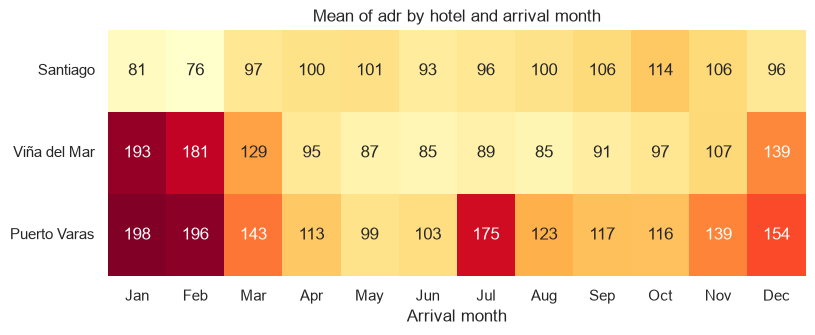

In [3]:
# ✏️ Change these settings
VALUE = "adr"       # "adr" (nightly rate) or "canceled" (cancellation rate)
AGG = "mean"        # "mean" or "median"

table = df.pivot_table(index="hotel", columns="arrival_month", values=VALUE, aggfunc=AGG).loc[HOTELS]
table.columns = MONTHS
plt.figure(figsize=(9, 3.2))
sns.heatmap(table, annot=True, fmt=".0f" if VALUE == "adr" else ".0%", cmap="YlOrRd", cbar=False)
plt.title(f"{AGG.capitalize()} of {VALUE} by hotel and arrival month")
plt.xlabel("Arrival month")
plt.ylabel("")
plt.show()

`idxmax()` and `idxmin()` give the column with the highest and lowest value in each row: each hotel's peak and low month.

In [4]:
for hotel in HOTELS:
    row = table.loc[hotel]
    print(f"{hotel:<13} peak {row.idxmax()} ({row.max():.2f}) · low {row.idxmin()} ({row.min():.2f}) · peak ÷ low {row.max() / row.min():.1f}x")

Santiago      peak Oct (113.87) · low Feb (76.35) · peak ÷ low 1.5x
Viña del Mar  peak Jan (192.78) · low Jun (84.56) · peak ÷ low 2.3x
Puerto Varas  peak Jan (198.28) · low May (99.21) · peak ÷ low 2.0x


**Think about it.** With `VALUE = "adr"`, what are each hotel's peak and low months, and how many times more is a peak night worth than a low one? What would happen if Altamar used one price calendar for the whole group?

<details><summary>Show the answer</summary>

Viña del Mar peaks in January (about 193 USD) and bottoms out in June (85): 2.3 times. Puerto Varas peaks in January (198) with a second peak in July (175, winter holidays), and is lowest in May (99). Santiago peaks in October (114) and is lowest in February (76): only 1.5 times, and in the opposite direction. One group calendar would raise Santiago's prices exactly when its business guests are away, and leave money on the table at the beach in January.
</details>

## <span class="hz-step-n">03</span> Weekends: who pays more?

`weekend_nights` counts the Friday and Saturday nights of a stay. The cell labels every booking as **Weekdays only**, **Weekend only**, or **Mixed**, and compares the average rate by hotel.

In [5]:
# ✏️ Change these settings
CUSTOMER = "All"     # "All", "Business", "Leisure" or "Group"

data = df if CUSTOMER == "All" else df[df["customer_type"] == CUSTOMER]
stay = np.select([data["weekend_nights"] == data["nights"], data["weekend_nights"] == 0], ["Weekend only", "Weekdays only"], "Mixed")
by_stay = data.assign(stay=stay).pivot_table(index="hotel", columns="stay", values="adr", aggfunc="mean").loc[HOTELS]
print(by_stay[["Weekdays only", "Mixed", "Weekend only"]].round(1), "\n")
for hotel in HOTELS:
    change = by_stay.loc[hotel, "Weekend only"] / by_stay.loc[hotel, "Weekdays only"] - 1
    print(f"{hotel:<13} a weekend-only stay costs {change:+.0%} compared with a weekdays-only stay")

stay          Weekdays only  Mixed  Weekend only
hotel                                           
Santiago              109.2   99.7          84.9
Viña del Mar          124.3  141.2         155.9
Puerto Varas          152.1  155.8         172.6 

Santiago      a weekend-only stay costs -22% compared with a weekdays-only stay
Viña del Mar  a weekend-only stay costs +25% compared with a weekdays-only stay
Puerto Varas  a weekend-only stay costs +13% compared with a weekdays-only stay


**Think about it.** Which hotel is cheaper on weekends, and which ones are pricier? Is it only because different customers stay on weekends? Try `CUSTOMER = "Business"` and `CUSTOMER = "Leisure"`. Explain the pattern from the business, not from the data.

<details><summary>Show the answer</summary>

Santiago's weekend-only stays cost about 22% less than weekday stays; Viña del Mar's cost about 25% more and Puerto Varas's about 13% more. The pattern holds for business and for leisure guests separately, so it is not just a different mix of customers. A city business hotel empties on Friday, when its corporate guests fly home, and discounts to fill rooms; beach and lake hotels fill on weekends, when leisure demand peaks. The same Saturday night is a low-demand night in Santiago and a high-demand night at the coast.
</details>

## <span class="hz-step-n">04</span> Booking early, cancelling more?

Operations wants to know whether bookings made far ahead are riskier. The cell cuts `lead_time_days` into **buckets** with `pd.cut` and computes the cancellation rate in each. `EDGES` are the upper limits of the buckets; the last bucket is "everything above".

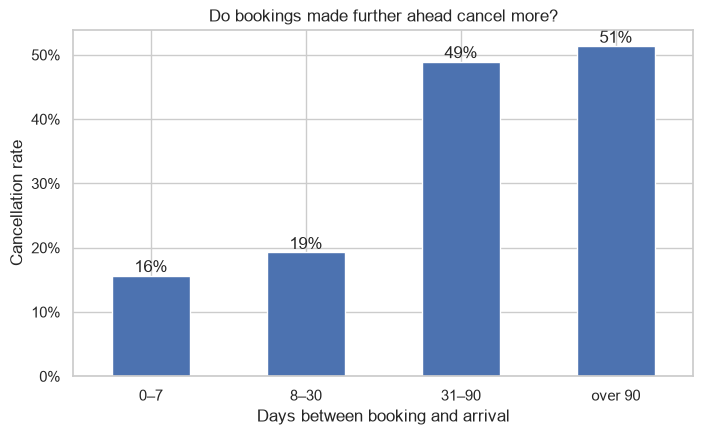

In [6]:
# ✏️ Change these settings
EDGES = [7, 30, 90]      # buckets 0–7, 8–30, 31–90 and over 90 days. Try [7, 30, 60, 90, 120, 180]

limits = [-1] + EDGES + [np.inf]
labels = [f"{a + 1}–{b}" for a, b in zip(limits[:-2], limits[1:-1])] + [f"over {EDGES[-1]}"]
labels[0] = f"0–{EDGES[0]}"
bucket = pd.cut(df["lead_time_days"], bins=limits, labels=labels)
by_lead = df.groupby(bucket, observed=True)["canceled"].agg(["count", "mean"])

ax = by_lead["mean"].plot.bar(figsize=(8, 4.5), rot=0)
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in by_lead["mean"]])
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.title("Do bookings made further ahead cancel more?")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Cancellation rate")
plt.show()

The same numbers as a table: `count` is how many bookings stand behind each rate.

In [7]:
by_lead.assign(rate=by_lead["mean"].map("{:.1%}".format)).drop(columns="mean")

,count,rate
lead_time_days,,
0–7,1047,15.7%
8–30,1963,19.3%
31–90,1945,48.9%
over 90,1009,51.3%


**Think about it.** With the four starting buckets, the rate rises from 16% to about 50% and then flattens. Now try `EDGES = [7, 30, 60, 90, 120, 180]`. What happens after 90 days? If you drew a single straight line through these bars, what would it predict for a booking made 300 days ahead?

<details><summary>Show the answer</summary>

The risk is not "the earlier, the riskier". It climbs to about 70% for bookings made 61–90 days ahead and then falls back to about 40% for bookings made more than four months ahead: a peak around three months out. A straight line would keep rising forever and predict that the earliest bookings are the riskiest, which is wrong. **A straight line will struggle** with this shape; week 5 brings models that can bend. (Check the `count` column too: buckets with few bookings give noisy rates.)
</details>

## <span class="hz-step-n">05</span> Three findings for the general manager

Pick a hotel. The cell prints the numbers you need: its seasons, its weekend effect and its riskiest bookings. Then write three findings in the cell below it, each as **what we see (with the number) → what it means for the business → what to check next**.

In [8]:
# ✏️ Change these settings
HOTEL = "Puerto Varas"     # "Santiago", "Viña del Mar" or "Puerto Varas"

h = df[df["hotel"] == HOTEL]
by_month = h.groupby("arrival_month")["adr"].mean()
weekend = h.loc[h["weekend_nights"] == h["nights"], "adr"].mean()
weekday = h.loc[h["weekend_nights"] == 0, "adr"].mean()
by_channel = h.groupby("channel")["canceled"].mean().sort_values()
print(f"{HOTEL}: {len(h):,} bookings, average rate USD {h['adr'].mean():.0f}, cancellation {h['canceled'].mean():.1%}")
print(f"Peak month {MONTHS[by_month.idxmax() - 1]} (USD {by_month.max():.0f}), low month {MONTHS[by_month.idxmin() - 1]} (USD {by_month.min():.0f})")
print(f"Weekend-only stays USD {weekend:.0f} vs weekdays-only USD {weekday:.0f}")
print(f"Cancellation: highest {by_channel.index[-1]} {by_channel.iloc[-1]:.1%}, lowest {by_channel.index[0]} {by_channel.iloc[0]:.1%}")

Puerto Varas: 1,493 bookings, average rate USD 156, cancellation 37.5%
Peak month Jan (USD 198), low month May (USD 99)
Weekend-only stays USD 173 vs weekdays-only USD 152
Cancellation: highest Online travel agency 42.7%, lowest Corporate 12.9%


**Your three findings** (double-click to edit this cell):

1. *What we see:* … → *What it means:* … → *Next:* …
2. *What we see:* … → *What it means:* … → *Next:* …
3. *What we see:* … → *What it means:* … → *Next:* …

<details><summary>Show an example for Puerto Varas</summary>

**Two high seasons, not one.** Puerto Varas's average rate peaks in January (198 USD) and again in July (175 USD, winter holidays), against 99 USD in May. *For revenue management:* July deserves its own pricing and marketing plan, like the summer. *Next:* does July sell out, or is there room to raise the rate further?

A good finding quotes a number the code printed, says who should act, and stops short of claiming a cause the data cannot prove.
</details>

## Graded quiz

Five questions on this week's ideas. They count for **5% of the module grade**, and **only your first submission counts**, so finish the lab before you start. Use the name and email you are registered with in the program.

<div class="hz-widget" data-widget="graded-quiz">
<script type="application/json">{"id": "session-2", "title": "Week 2 quiz", "questions": [{"q": "A summary of the raw file lists seven hotels for a group that owns three. What is the right fix?", "options": ["Map each spelling (SANTIAGO, Pto. Varas…) to its official name, and record it in the cleaning log", "Keep the seven groups: they are different systems", "Drop the bookings of the four extra hotels", "Delete the hotel column"]}, {"q": "In the clean file, the mean of <code>canceled</code> for bookings made 61–90 days ahead is 0.70. What does it mean?", "options": ["70 bookings in that range were cancelled", "70% of the bookings made 61–90 days ahead were cancelled", "Bookings in that range are 70% likely to be made by an online travel agency", "70% of all cancellations come from that range"]}, {"q": "Which chart best answers \"does each hotel have its own seasons?\"", "options": ["A line chart of the average adr by arrival month, one line per hotel", "A histogram of adr", "A bar chart of the cancellation rate by hotel", "A box plot of adr by hotel"]}, {"q": "Santiago's weekend-only stays cost about 22% less than its weekday stays, while Viña del Mar's cost about 25% more. What is the most sensible business explanation?", "options": ["Santiago lives on business travellers who leave on Friday, so weekend demand drops; beach demand peaks on weekends", "Santiago's data has errors on weekends", "Weekend guests always book cheaper rooms", "Viña del Mar charges a cleaning fee on weekends"]}, {"q": "The cancellation rate rises from 16% (0–7 days ahead) to about 70% (61–90 days), then falls to about 40% for bookings made more than four months ahead. What does this mean for a model?", "options": ["The further ahead, the higher the risk, with no limit", "Bookings made far ahead should be deleted as outliers", "Lead time is useless for predicting cancellations", "A straight line through lead time will miss the peak: the effect rises and then falls"]}]}</script>
</div>